<!-- notebook-header -->
<a href="https://pedramjahangiry.com"><img src="https://raw.githubusercontent.com/PJalgotrader/advanced-timeseries-forecasting/main/assets/header/banner.png?v=2" alt="Dr. Pedram Jahangiry: ML, deep learning and time series, explained visually" width="100%"></a>

<a href="https://colab.research.google.com/github/PJalgotrader/advanced-timeseries-forecasting/blob/main/07-deep-sequence-models/01_rnn_lstm_one_series.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a> &nbsp; Run it in Colab. To keep your changes, choose **File → Save a copy in Drive** first.

<a href="https://youtu.be/X6PwdT5-V_Q"><img src="https://img.shields.io/badge/Watch_the_video-D0A63C?style=for-the-badge&logo=youtube&logoColor=0A1020" alt="Watch the video"></a> <a href="https://www.youtube.com/playlist?list=PLG1FN7Dkkeu8"><img src="https://img.shields.io/badge/Deep_Forecasting_2027-0A1020?style=for-the-badge&logo=youtube&logoColor=E8C468" alt="Deep Forecasting 2027"></a> <a href="https://pedramjahangiry.com"><img src="https://img.shields.io/badge/pedramjahangiry.com-0A1020?style=for-the-badge&logo=googlechrome&logoColor=E8C468" alt="pedramjahangiry.com"></a> <a href="https://pedramjahangiry.com/newsletter.html"><img src="https://img.shields.io/badge/Newsletter-0A1020?style=for-the-badge&logo=substack&logoColor=E8C468" alt="Newsletter"></a> <a href="https://www.youtube.com/@pedramjahangiry"><img src="https://img.shields.io/badge/YouTube-0A1020?style=for-the-badge&logo=youtube&logoColor=E8C468" alt="YouTube"></a> <a href="https://www.linkedin.com/in/pedram-jahangiry-cfa-5778015a"><img src="https://img.shields.io/badge/LinkedIn-0A1020?style=for-the-badge&logo=linkedin&logoColor=E8C468" alt="LinkedIn"></a> <a href="https://x.com/pjalgo"><img src="https://img.shields.io/badge/%40pjalgo-0A1020?style=for-the-badge&logo=x&logoColor=E8C468" alt="@pjalgo"></a> <a href="https://github.com/PJalgotrader"><img src="https://img.shields.io/badge/GitHub-0A1020?style=for-the-badge&logo=github&logoColor=E8C468" alt="GitHub"></a>

---

# RNN and LSTM for one time series, in Keras

The code for the video **"RNN and LSTM in Python: Forecasting a Time Series with Keras, Step by Step"** (Deep Forecasting, Module 7, part 4 of 5).
The theory is in the three videos before it: dense network vs RNN, the RNN, the LSTM.

Every forecasting project in this repository follows the same six steps, and reports three forecasting horizons
(one step ahead, multi-step, multi-output; section 7):

1. the data, split by time
2. prepare it, using the training part only
3. cut it into windows
4. a baseline to beat
5. build and train a model
6. score it in real units, more than once

Setup is not covered here: it changes every year. Watch the setup video for the current year, and see the
"Tested with" table in the README.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers

print("keras", keras.__version__, "on", keras.backend.backend())

I0000 00:00:1795226495.275410 1765400 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795226496.028864 1765400 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


keras 3.15.1 on tensorflow


## 1. The data, split by time

Airline passengers per month, in thousands, 1949 to 1960: 144 months. The last 12 months are the **test** year. The
24 months before it are for **validation** (deciding when to stop training). Everything earlier is for **training**.
Never shuffle a time series before splitting it: the model would be trained on the future.

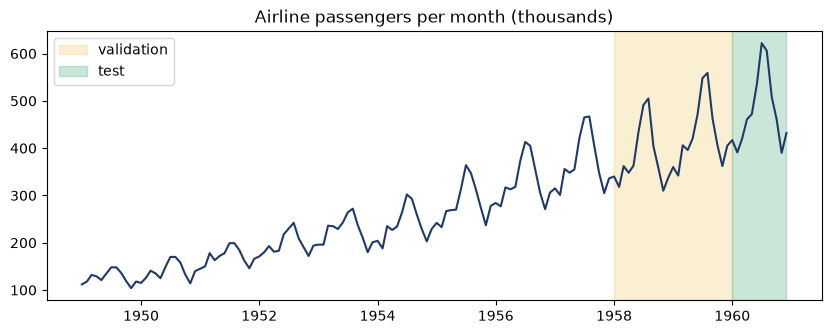

In [2]:
try:
    df = pd.read_csv("../data/airline_passengers.csv")
except FileNotFoundError:   # running somewhere without the repository, for example in a hosted notebook
    df = pd.read_csv("https://raw.githubusercontent.com/PJalgotrader/advanced-timeseries-forecasting/main/data/airline_passengers.csv")

passengers = df["Passengers"].to_numpy("float32")
months = pd.to_datetime(df["Month"])
N_TEST, N_VAL = 12, 24

plt.figure(figsize=(10, 3.5))
plt.plot(months, passengers, color="#1f3a68")
plt.axvspan(months.iloc[-N_TEST - N_VAL], months.iloc[-N_TEST], color="#f2c14e", alpha=0.25, label="validation")
plt.axvspan(months.iloc[-N_TEST], months.iloc[-1], color="#2e9e6b", alpha=0.25, label="test")
plt.title("Airline passengers per month (thousands)"); plt.legend(); plt.show()

## 2. Prepare it

A recurrent layer squeezes its state through tanh, which is flat for large numbers. Fed raw values like 112 or 400,
every unit sits at 1 and the forecast is one flat line (measured in the "dense network vs RNN" video). So:

- take the **logarithm**: the seasonal swings stop growing with the level
- take the **difference**: the trend is gone, and what is left is small, around zero

`change[i]` is the change of the log from month `i` to month `i + 1`. That is the series the networks see.

143 changes, from -0.22 to 0.22


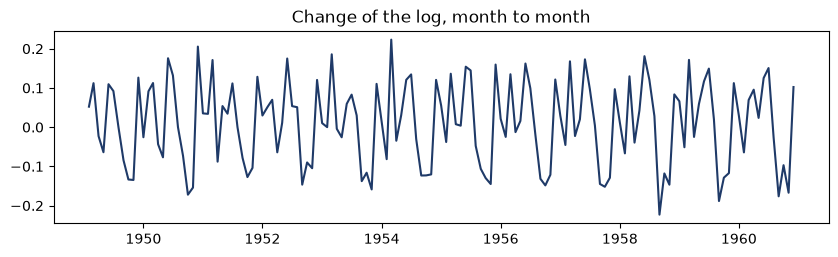

In [3]:
change = np.diff(np.log(passengers))            # 143 values, roughly between -0.2 and +0.2
print(len(change), "changes, from", change.min().round(2), "to", change.max().round(2))

plt.figure(figsize=(10, 2.5)); plt.plot(months[1:], change, color="#1f3a68")
plt.title("Change of the log, month to month"); plt.show()

## 3. Cut it into windows

One sample is a **window**: **Tx** values in, **Ty** values out. Here Tx = 12 months in and Ty = 1, the next month
(Ty = 12 comes back in section 7). A few lines of NumPy, nothing hidden.
A recurrent layer wants the shape **(samples, time steps, features)**: here (samples, 12, 1).

The test windows reach back into the validation months for their inputs. That is fine: at forecast time those
months are in the past. What matters is that no test **target** was used for training.

In [4]:
Tx, Ty = 12, 1                                  # Tx values in, Ty values out

def make_windows(series, Tx, Ty, start, end):
    """Every window of Tx inputs whose Ty targets all lie in series[start:end]."""
    ts = range(start, end - Ty + 1)
    X = np.stack([series[t - Tx:t] for t in ts])
    y = np.stack([series[t:t + Ty] for t in ts])
    return X[..., None], y                      # the None adds the last axis: 1 feature

n = len(change)
test_start, val_start = n - N_TEST, n - N_TEST - N_VAL
X_train, y_train = make_windows(change, Tx, Ty, Tx, val_start)
X_val, y_val = make_windows(change, Tx, Ty, val_start, test_start)
X_test, y_test = make_windows(change, Tx, Ty, test_start, n)

for name, X in [("train", X_train), ("validation", X_val), ("test", X_test)]:
    print(f"{name:10s} {X.shape}")
print("\nfirst window:", X_train[0, :, 0].round(3), "-> target", y_train[0, 0].round(3))

train      (95, 12, 1)
validation (24, 12, 1)
test       (12, 12, 1)

first window: [ 0.052  0.112 -0.023 -0.064  0.109  0.092  0.    -0.085 -0.134 -0.135
  0.126 -0.026] -> target 0.091


## 4. A baseline to beat

Scores are in **passengers**, not in changes of logs: undo the difference and the logarithm first. A forecast of
next month is this month times e to the forecast change.

Two baselines that need no training: "next month = this month", and "next month = the same month last year".

In [5]:
actual = passengers[test_start + 1:]            # the 12 months of the test year

def to_passengers(change_forecast):
    """Undo the difference and the log: next month = this month x exp(forecast change)."""
    return passengers[test_start:-1] * np.exp(change_forecast)

def score(forecast):
    """Mean absolute percentage error over the test year."""
    return float(np.mean(np.abs(forecast - actual) / actual) * 100)

results = {"this month again": score(passengers[test_start:-1]),
           "same month last year": score(passengers[test_start + 1 - 12:-12])}
for name, value in results.items():
    print(f"{name:22s} {value:5.1f}%")

this month again         9.5%
same month last year    10.0%


## 5. Build and train a model

### The simple RNN

`SimpleRNN(16)` is the recurrent cell of the theory videos with 16 slots of memory. Its parameters:
1 x 16 weights on the input, 16 x 16 on the previous state, 16 biases: **288**. The `Dense(1)` on top turns the last
state into one number: 16 weights and 1 bias.

In [6]:
def build(*hidden_layers, Ty=1):
    """A model that reads a window of Tx months with 1 feature and returns Ty numbers."""
    inputs = keras.Input(shape=(Tx, 1))
    x = inputs
    for layer in hidden_layers:
        x = layer(x)
    return keras.Model(inputs, layers.Dense(Ty)(x))

model = build(layers.SimpleRNN(16))
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 12, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 16)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305 (1.19 KB)

 Trainable params: 305 (1.19 KB)

 Non-trainable params: 0 (0.00 B)

Training stops when the validation loss has not improved for 40 epochs, and the weights of the best epoch are kept.
That one callback replaces guessing the number of epochs.

In [7]:
def train(model, verbose=0, data=None):
    """Train with early stopping; data = (X_train, y_train, X_val, y_val), the Ty = 1 windows unless given."""
    Xt, yt, Xv, yv = data or (X_train, y_train, X_val, y_val)
    model.compile(optimizer=keras.optimizers.Adam(0.003), loss="mse")
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=40, restore_best_weights=True)
    return model.fit(Xt, yt, validation_data=(Xv, yv),
                     epochs=400, batch_size=16, callbacks=[stop], verbose=verbose)

keras.utils.set_random_seed(0)
model = build(layers.SimpleRNN(16))
history = train(model, verbose=2)

Epoch 1/400
6/6 - 1s - 112ms/step - loss: 0.0195 - val_loss: 0.0111
Epoch 2/400
6/6 - 0s - 10ms/step - loss: 0.0089 - val_loss: 0.0078
Epoch 3/400
6/6 - 0s - 12ms/step - loss: 0.0060 - val_loss: 0.0057
Epoch 4/400
6/6 - 0s - 9ms/step - loss: 0.0045 - val_loss: 0.0045
Epoch 5/400
6/6 - 0s - 14ms/step - loss: 0.0034 - val_loss: 0.0031
Epoch 6/400
6/6 - 0s - 11ms/step - loss: 0.0031 - val_loss: 0.0025
Epoch 7/400
6/6 - 0s - 9ms/step - loss: 0.0027 - val_loss: 0.0022
Epoch 8/400
6/6 - 0s - 11ms/step - loss: 0.0025 - val_loss: 0.0019
Epoch 9/400
6/6 - 0s - 9ms/step - loss: 0.0023 - val_loss: 0.0016
Epoch 10/400
6/6 - 0s - 10ms/step - loss: 0.0023 - val_loss: 0.0015
Epoch 11/400
6/6 - 0s - 9ms/step - loss: 0.0022 - val_loss: 0.0014
Epoch 12/400
6/6 - 0s - 10ms/step - loss: 0.0021 - val_loss: 0.0014
Epoch 13/400
6/6 - 0s - 10ms/step - loss: 0.0021 - val_loss: 0.0013
Epoch 14/400
6/6 - 0s - 9ms/step - loss: 0.0020 - val_loss: 0.0013
Epoch 15/400
6/6 - 0s - 10ms/step - loss: 0.0020 - val_loss: 

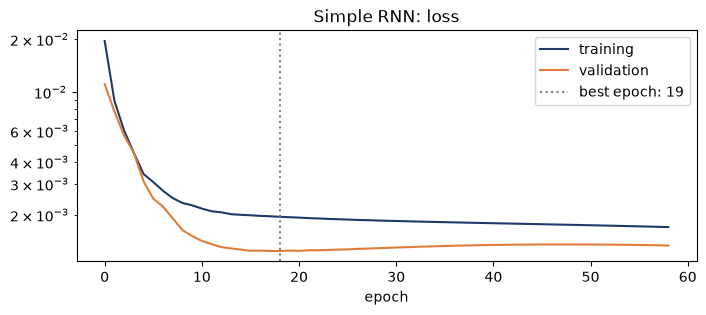

In [8]:
def plot_history(history, title):
    best = int(np.argmin(history.history["val_loss"]))
    plt.figure(figsize=(8, 3))
    plt.plot(history.history["loss"], label="training", color="#1f3a68")
    plt.plot(history.history["val_loss"], label="validation", color="#e07b39")
    plt.axvline(best, color="grey", ls=":", label=f"best epoch: {best + 1}")
    plt.yscale("log"); plt.xlabel("epoch"); plt.title(title); plt.legend(); plt.show()

plot_history(history, "Simple RNN: loss")

simple RNN, this run: 3.7%


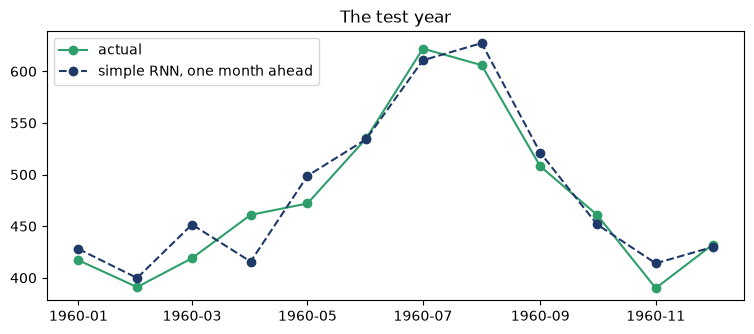

In [9]:
def forecast(model):
    return to_passengers(model.predict(X_test, verbose=0)[:, 0])

rnn_forecast = forecast(model)
print(f"simple RNN, this run: {score(rnn_forecast):.1f}%")

plt.figure(figsize=(9, 3.5))
plt.plot(months.iloc[-N_TEST:], actual, "o-", color="#2e9e6b", label="actual")
plt.plot(months.iloc[-N_TEST:], rnn_forecast, "o--", color="#1f3a68", label="simple RNN, one month ahead")
plt.title("The test year"); plt.legend(); plt.show()

### The LSTM

One word changes. The LSTM has three gates and a candidate, each with its own copy of the RNN's weights:
4 x 288 = **1,152** parameters.

In [10]:
build(layers.LSTM(16)).summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 12, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 16)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,169 (4.57 KB)

 Trainable params: 1,169 (4.57 KB)

 Non-trainable params: 0 (0.00 B)

### Stacking layers

The first recurrent layer has to hand over its state at **every** step, not only the last one, so that the second
layer has a sequence to read: `return_sequences=True`. Its output shape becomes (12, 32) instead of (32).

**Two kinds of dropout** (both during training only, neither adds a parameter):

- `layers.Dropout(0.1)`, a layer of its own. Here it sits after the last recurrent layer, so it switches off each of
  the 32 slots of the final state with probability 10% (a new pick for every window at every training step) and
  scales the rest by 1 / 0.9. It never touches the loop.
- `recurrent_dropout=0.1`, an argument of the recurrent layer. It acts inside the loop, on the previous state just
  before it is multiplied by U, with **the same pick at all 12 steps** of a window (a new pick for the next window).
  For LSTM and GRU layers it also switches off Keras's fast GPU routine.
- `dropout=0.1` inside the recurrent layer does the same to the inputs. With one feature, that would erase a whole
  window now and then.

In [11]:
build(layers.SimpleRNN(32, return_sequences=True),
      layers.SimpleRNN(32),
      layers.Dropout(0.1)).summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 12, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ (None, 12, 32)         │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_3 (SimpleRNN)        │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,201 (12.50 KB)

 Trainable params: 3,201 (12.50 KB)

 Non-trainable params: 0 (0.00 B)

### Reading the window in both directions

`Bidirectional` runs two copies of the layer, one from the first month to the last and one backwards, and joins
their states: 2 x 16 = 32 numbers. It helps with text, where a later word explains an earlier one. In a
forecasting window the latest months matter most, and the backward copy reads them first and has 11 more steps to
forget them.

In [12]:
build(layers.Bidirectional(layers.SimpleRNN(16))).summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 12, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 32)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 609 (2.38 KB)

 Trainable params: 609 (2.38 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Score it in real units, more than once

One training run is one draw: the starting weights are random. So each model is trained **five times** and the
table shows the middle run and the range. Judge a model by that, never by its best run.

In [13]:
candidates = {
    "dense network (32, 16)": lambda: build(layers.Flatten(), layers.Dense(32, activation="relu"), layers.Dense(16, activation="relu")),
    "simple RNN (16)":        lambda: build(layers.SimpleRNN(16)),
    "LSTM (16)":              lambda: build(layers.LSTM(16)),
    "two RNN layers (32, 32)": lambda: build(layers.SimpleRNN(32, return_sequences=True), layers.SimpleRNN(32), layers.Dropout(0.1)),
    "bidirectional RNN (16)": lambda: build(layers.Bidirectional(layers.SimpleRNN(16))),
}
RUNS = 5
table = []
for name, make in candidates.items():
    errors = []
    for seed in range(RUNS):
        keras.utils.set_random_seed(seed)
        model = make()
        train(model)
        errors.append(score(forecast(model)))
    table.append({"model": name, "parameters": model.count_params(), "median %": np.median(errors), "best %": min(errors), "worst %": max(errors)})
    print(f"{name:26s} {np.median(errors):4.1f}%   ({min(errors):.1f} to {max(errors):.1f})")

table = pd.DataFrame(table).round(1)
table

dense network (32, 16)      3.7%   (3.4 to 4.2)
simple RNN (16)             3.3%   (2.8 to 3.7)
LSTM (16)                   3.6%   (2.9 to 3.7)
two RNN layers (32, 32)     3.7%   (3.1 to 3.8)
bidirectional RNN (16)      3.4%   (3.4 to 3.9)


,model,parameters,median %,best %,worst %
0,"dense network (32, 16)",961,3.7,3.4,4.2
1,simple RNN (16),305,3.3,2.8,3.7
2,LSTM (16),1169,3.6,2.9,3.7
3,"two RNN layers (32, 32)",3201,3.7,3.1,3.8
4,bidirectional RNN (16),609,3.4,3.4,3.9


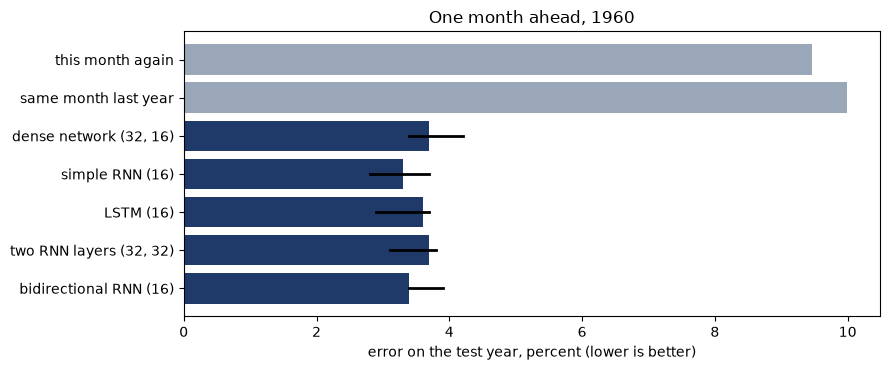

In [14]:
plt.figure(figsize=(9, 3.8))
names = list(results) + list(table["model"])
values = list(results.values()) + list(table["median %"])
bars = plt.barh(names[::-1], values[::-1], color=(["#1f3a68"] * len(table) + ["#9aa7b8"] * len(results)))
for name, lo, hi in zip(table["model"], table["best %"], table["worst %"]):
    plt.plot([lo, hi], [name, name], color="black", lw=2)
plt.xlabel("error on the test year, percent (lower is better)"); plt.title("One month ahead, 1960"); plt.tight_layout(); plt.show()

## 7. Three forecasting horizons: one step, multi-step, multi-output

Everything above is **one step ahead**: each month of 1960 is forecast from the 12 *real* months before it. That
flatters every model, because in real life you do not know February when you forecast it in December. Preparing the
data with **Tx** (values in) and **Ty** (values out) gives two honest ways to forecast the whole year from
December 1959:

- **multi-step** (recursive): the same Ty = 1 model forecasts January; that forecast becomes its newest input; it
  forecasts February; and so on, 12 times. Errors can pile up.
- **multi-output** (direct): a model with **Ty = 12** outputs forecasts all 12 months in one shot.

Each model is trained 10 times here: the two whole-year forecasts move far more from run to run than one step
ahead, and 5 runs are not enough to find their middle.

There is a separate video on the three horizons, in theory and in Python, for any model. Classical models such as
seasonal ARIMA and ETS forecast multi-step by their nature; multi-output would take one model per month ahead.

In [15]:
def multi_step(model):
    """Recursive: forecast one month, append it to the inputs, repeat until the 12 months of 1960 are done."""
    window, path = list(change[test_start - Tx:test_start]), []
    for _ in range(N_TEST):
        x = np.array(window[-Tx:], "float32")[None, :, None]
        step = float(keras.ops.convert_to_numpy(model(x, training=False))[0, 0])   # calling the model directly: faster than predict for one window
        path.append(step); window.append(step)
    return passengers[test_start] * np.exp(np.cumsum(path))       # December 1959 x the accumulated changes

H = N_TEST                                                     # Ty = 12: all of 1960 at once
X_train12, y_train12 = make_windows(change, Tx, H, Tx, val_start)
X_val12, y_val12 = make_windows(change, Tx, H, val_start, test_start)
X_last = change[test_start - Tx:test_start][None, :, None]      # the 12 months up to December 1959
print("Ty = 12 windows:", X_train12.shape, y_train12.shape, "| validation", X_val12.shape)

def multi_output(model):
    return passengers[test_start] * np.exp(np.cumsum(model.predict(X_last, verbose=0)[0]))

Ty = 12 windows: (84, 12, 1) (84, 12) | validation (13, 12, 1)


In [16]:
horizon_models = {
    "dense network (32, 16)": lambda Ty: build(layers.Flatten(), layers.Dense(32, activation="relu"), layers.Dense(16, activation="relu"), Ty=Ty),
    "simple RNN (16)":        lambda Ty: build(layers.SimpleRNN(16), Ty=Ty),
    "LSTM (16)":              lambda Ty: build(layers.LSTM(16), Ty=Ty),
}
HORIZON_RUNS = 10                # multi-step and multi-output move far more from run to run than one step: 10 runs, not 5
horizons, paths = [], {}
for name, make in horizon_models.items():
    one, rec, direct = [], [], []
    for seed in range(HORIZON_RUNS):
        keras.utils.set_random_seed(seed)
        m1 = make(1); train(m1)
        one.append(score(forecast(m1))); rec_path = multi_step(m1); rec.append(score(rec_path))
        keras.utils.set_random_seed(seed)
        m12 = make(H); train(m12, data=(X_train12, y_train12, X_val12, y_val12))
        mo_path = multi_output(m12); direct.append(score(mo_path))
        if seed == 0: paths[name] = (rec_path, mo_path)
    horizons.append({"model": name, "one step %": np.median(one), "multi-step %": np.median(rec), "multi-output %": np.median(direct)})
    print(f"{name:24s} one step {np.median(one):4.1f}%   multi-step {np.median(rec):4.1f}%   multi-output {np.median(direct):4.1f}%   (middle of {HORIZON_RUNS} runs)")

horizons = pd.DataFrame(horizons).round(1)
horizons

dense network (32, 16)   one step  3.8%   multi-step  3.9%   multi-output  4.3%   (middle of 10 runs)
simple RNN (16)          one step  3.2%   multi-step  4.1%   multi-output  4.7%   (middle of 10 runs)
LSTM (16)                one step  3.6%   multi-step  4.1%   multi-output  4.9%   (middle of 10 runs)


,model,one step %,multi-step %,multi-output %
0,"dense network (32, 16)",3.8,3.9,4.3
1,simple RNN (16),3.2,4.1,4.7
2,LSTM (16),3.6,4.1,4.9


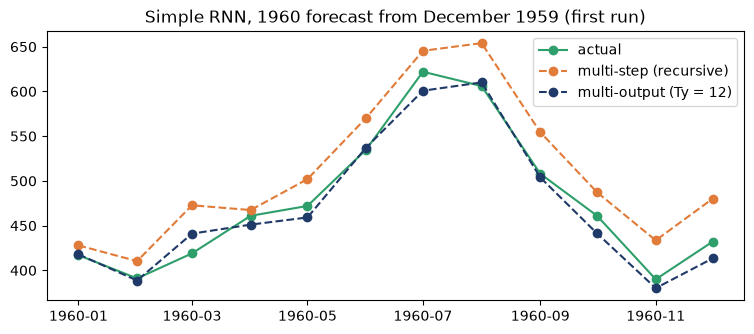

In [17]:
rec_path, mo_path = paths["simple RNN (16)"]
plt.figure(figsize=(9, 3.5))
plt.plot(months.iloc[-N_TEST:], actual, "o-", color="#2e9e6b", label="actual")
plt.plot(months.iloc[-N_TEST:], rec_path, "o--", color="#e07b39", label="multi-step (recursive)")
plt.plot(months.iloc[-N_TEST:], mo_path, "o--", color="#1f3a68", label="multi-output (Ty = 12)")
plt.title("Simple RNN, 1960 forecast from December 1959 (first run)"); plt.legend(); plt.show()

## What this shows

- One step ahead flatters every model. Forecast the whole of 1960 from December (multi-step or multi-output) and
  the middle run gets worse, and the spread between runs gets much larger: one number from one run tells you little.
- Every network beats the two baselines by a wide margin, and they land within about half a percentage point of
  each other. On 144 well-behaved months, more layers and gates buy nothing.
- The classical "airline model" (a seasonal ARIMA with two parameters) scores about 3.0% one step ahead and about
  2.9% for the whole year forecast from December; ETS about 4.1% and 4.3%. For a small, regular series, start there.
- What carries over to bigger problems is the recipe: split by time, prepare with the training part, windows,
  a baseline, early stopping, scores in real units, several runs. The next notebook uses it on weather data with
  14 features and 420,000 rows.

## Try it yourself, with a coding assistant

Good things to ask an AI coding assistant, with this notebook open:

- "Use 24 months of history instead of 12." (Change Tx, and check how many windows are left.)
- "Add the GRU to the three-horizon table."
- "Swap the airline data for my own monthly series."
- "Port this to PyTorch." or "Update this for the current version of Keras."

And always check what you get back: the shapes of the windows, that the split is by time, that the baseline is
still there, and that the score is measured on months the model never trained on.